# Milestone 2: SME Application Credit Scorecard

## Objective

Develop a leakage-safe application scorecard that estimates the probability of default within 12 months.

The development process includes:

- Modelling-population and target validation
- Leakage identification
- Stratified train-test split
- Missing-value and outlier treatment
- Weight of Evidence and Information Value analysis
- Logistic-regression scorecard
- Discrimination, calibration and rank-ordering validation
- Score scaling and risk-band creation

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

# Find the project root whether the notebook starts from /notebooks or the repo root
current_path = Path.cwd()

project_root = next(
    (
        path for path in [current_path, *current_path.parents]
        if (path / "data/raw/sme_applicant_portfolio.csv").exists()
    ),
    None
)

assert project_root is not None, "Project root or portfolio dataset could not be found."

data_path = project_root / "data/raw/sme_applicant_portfolio.csv"
portfolio = pd.read_csv(data_path)

print("Project root:", project_root)
print("Dataset:", data_path)
print("Portfolio shape:", portfolio.shape)

display(portfolio.head())

Project root: /workspaces/SME-Lending-Decision-Analytics
Dataset: /workspaces/SME-Lending-Decision-Analytics/data/raw/sme_applicant_portfolio.csv
Portfolio shape: (15000, 22)


,applicant_id,industry,region,entity_type,years_in_business,employees,annual_revenue,revenue_growth_12m,profit_margin,net_income,total_debt,current_ratio,dscr,leverage,bureau_score,credit_history_months,prior_delinquencies_12m,utilization,public_records,requested_amount,collateral_flag,default_12m
0,SME000001,Retail,North,Proprietorship,8.4000,6,"8,127,000.0000",0.0293,0.0106,"86,100.0000","4,755,000.0000",1.4900,1.0800,0.5851,774,118,0,0.3226,0,"1,939,000.0000",1,0
1,SME000002,Transport,West,LLP,4.6000,19,"30,290,000.0000",-0.0745,0.1365,"4,134,600.0000","45,847,000.0000",1.3000,1.1400,1.5136,766,84,0,0.3914,0,"3,746,000.0000",1,0
2,SME000003,Healthcare,East,Proprietorship,7.6000,15,"6,503,000.0000",0.3306,-0.0230,"-149,600.0000","6,715,000.0000",1.4600,1.4400,1.0326,747,110,0,0.4214,0,"1,313,000.0000",1,0
3,SME000004,Professional Services,South,Private Limited,11.3000,33,"21,575,000.0000",0.4279,0.1615,"3,484,400.0000","10,114,000.0000",0.7500,1.0400,0.4688,699,158,0,0.5366,0,"7,482,000.0000",0,0
4,SME000005,Professional Services,South,Proprietorship,9.2000,17,"14,393,000.0000",-0.1981,0.1320,"1,899,900.0000","2,166,000.0000",1.7400,1.1900,0.1505,709,122,0,0.3827,0,"2,009,000.0000",0,0


## 1. Modelling Population and Target Validation

Before selecting predictors, we validate:

- One row represents one loan applicant
- Applicant IDs are unique
- The target is binary and complete
- Class distribution is sufficient for stratified sampling
- No duplicate applications are present

In [2]:
TARGET = "default_12m"
ID_COLUMN = "applicant_id"

assert TARGET in portfolio.columns, f"{TARGET} is missing."
assert ID_COLUMN in portfolio.columns, f"{ID_COLUMN} is missing."

column_audit = pd.DataFrame({
    "column": portfolio.columns,
    "data_type": portfolio.dtypes.astype(str).values,
    "missing_count": portfolio.isna().sum().values,
    "missing_pct": (
        portfolio.isna().mean().mul(100).round(2).values
    ),
    "unique_values": portfolio.nunique(dropna=False).values
})

print("Number of rows:", len(portfolio))
print("Number of columns:", portfolio.shape[1])
print("Unique applicant IDs:", portfolio[ID_COLUMN].nunique())
print("Duplicate applicant IDs:", portfolio[ID_COLUMN].duplicated().sum())
print("Fully duplicated rows:", portfolio.duplicated().sum())
print("Missing target values:", portfolio[TARGET].isna().sum())
print("Target values:", sorted(portfolio[TARGET].dropna().unique()))

target_summary = (
    portfolio[TARGET]
    .value_counts(dropna=False)
    .rename_axis("default_12m")
    .to_frame("applicants")
)

target_summary["percentage"] = (
    target_summary["applicants"] / len(portfolio) * 100
).round(2)

display(column_audit)
display(target_summary)

Number of rows: 15000
Number of columns: 22
Unique applicant IDs: 15000
Duplicate applicant IDs: 0
Fully duplicated rows: 0
Missing target values: 0
Target values: [np.int64(0), np.int64(1)]


,column,data_type,missing_count,missing_pct,unique_values
0,applicant_id,str,0,0.0000,15000
1,industry,str,0,0.0000,10
2,region,str,0,0.0000,5
3,entity_type,str,0,0.0000,5
4,years_in_business,float64,0,0.0000,316
5,employees,int64,0,0.0000,173
6,annual_revenue,float64,0,0.0000,12892
7,revenue_growth_12m,float64,0,0.0000,7110
8,profit_margin,float64,0,0.0000,2991
9,net_income,float64,0,0.0000,13068


,applicants,percentage
default_12m,,
0,11547,76.9800
1,3453,23.0200


## 2. Feature Inventory and Leakage Audit

Only information available at the application decision date can be used as a predictor.

Identifiers and the subsequent 12-month performance outcome are excluded. Financial
variables that are related to one another are not necessarily leakage; their redundancy
and multicollinearity will be tested later.

In [3]:
identifier_columns = ["applicant_id"]
target_columns = ["default_12m"]

categorical_features = [
    "industry",
    "region",
    "entity_type"
]

numeric_features = [
    "years_in_business",
    "employees",
    "annual_revenue",
    "revenue_growth_12m",
    "profit_margin",
    "net_income",
    "total_debt",
    "current_ratio",
    "dscr",
    "leverage",
    "bureau_score",
    "credit_history_months",
    "prior_delinquencies_12m",
    "utilization",
    "public_records",
    "requested_amount",
    "collateral_flag"
]

candidate_features = categorical_features + numeric_features

# Post-outcome fields that would be prohibited if present
leakage_deny_list = [
    "default_date",
    "days_past_due_12m",
    "max_dpd_12m",
    "write_off_flag",
    "recovery_amount",
    "collection_status",
    "actual_loss_amount"
]

classified_columns = (
    identifier_columns
    + target_columns
    + candidate_features
)

assert len(classified_columns) == len(set(classified_columns)), \
    "A column was assigned to more than one role."

assert set(classified_columns) == set(portfolio.columns), \
    f"Unclassified columns: {set(portfolio.columns) - set(classified_columns)}"

assert not set(candidate_features).intersection(identifier_columns)
assert not set(candidate_features).intersection(target_columns)
assert not set(candidate_features).intersection(leakage_deny_list)

feature_inventory = pd.DataFrame({
    "column": portfolio.columns,
    "role": [
        "Identifier – exclude"
        if column in identifier_columns
        else "Target – exclude from predictors"
        if column in target_columns
        else "Candidate categorical predictor"
        if column in categorical_features
        else "Candidate numeric predictor"
        for column in portfolio.columns
    ]
})

print("Candidate predictors:", len(candidate_features))
print("Categorical predictors:", len(categorical_features))
print("Numeric predictors:", len(numeric_features))
print("Direct leakage detected: No")

display(feature_inventory)

Candidate predictors: 20
Categorical predictors: 3
Numeric predictors: 17
Direct leakage detected: No


,column,role
0,applicant_id,Identifier – exclude
1,industry,Candidate categorical predictor
2,region,Candidate categorical predictor
3,entity_type,Candidate categorical predictor
4,years_in_business,Candidate numeric predictor
5,employees,Candidate numeric predictor
6,annual_revenue,Candidate numeric predictor
7,revenue_growth_12m,Candidate numeric predictor
8,profit_margin,Candidate numeric predictor
9,net_income,Candidate numeric predictor


## 3. Stratified Development–Validation Split

The portfolio is divided into:

- **70% development sample:** used for EDA, binning, feature selection and model fitting
- **30% validation sample:** kept unseen for final model evaluation

Stratification preserves the portfolio default rate in both samples.

Because the dataset has no application-date field, an out-of-time split is not possible.
This is recorded as a limitation of the current synthetic dataset.

In [4]:
from sklearn.model_selection import train_test_split

RANDOM_SEED = 2026

development_sample, validation_sample = train_test_split(
    portfolio,
    test_size=0.30,
    random_state=RANDOM_SEED,
    stratify=portfolio[TARGET]
)

development_sample = development_sample.reset_index(drop=True)
validation_sample = validation_sample.reset_index(drop=True)

# Separate predictors and target
X_dev = development_sample[candidate_features].copy()
y_dev = development_sample[TARGET].copy()

X_val = validation_sample[candidate_features].copy()
y_val = validation_sample[TARGET].copy()

# Ensure no applicant appears in both samples
id_overlap = set(development_sample[ID_COLUMN]).intersection(
    set(validation_sample[ID_COLUMN])
)

split_summary = pd.DataFrame({
    "sample": ["Full portfolio", "Development", "Validation"],
    "observations": [
        len(portfolio),
        len(development_sample),
        len(validation_sample)
    ],
    "defaults": [
        portfolio[TARGET].sum(),
        y_dev.sum(),
        y_val.sum()
    ],
    "non_defaults": [
        (portfolio[TARGET] == 0).sum(),
        (y_dev == 0).sum(),
        (y_val == 0).sum()
    ],
    "default_rate": [
        portfolio[TARGET].mean(),
        y_dev.mean(),
        y_val.mean()
    ]
})

assert len(development_sample) + len(validation_sample) == len(portfolio)
assert len(id_overlap) == 0, "Applicant leakage across samples detected."
assert abs(y_dev.mean() - y_val.mean()) < 0.001

print("Development shape:", X_dev.shape)
print("Validation shape:", X_val.shape)
print("Applicant overlap:", len(id_overlap))

display(
    split_summary.style.format({
        "observations": "{:,.0f}",
        "defaults": "{:,.0f}",
        "non_defaults": "{:,.0f}",
        "default_rate": "{:.2%}"
    })
)

Development shape: (10500, 20)
Validation shape: (4500, 20)
Applicant overlap: 0


,sample,observations,defaults,non_defaults,default_rate
0,Full portfolio,"15,000","3,453","11,547",23.02%
1,Development,"10,500","2,417","8,083",23.02%
2,Validation,"4,500","1,036","3,464",23.02%


## 4. Development-Sample Range and Outlier Audit

Hard validity rules identify impossible values such as negative revenue or utilization
outside 0–100%.

Statistical outlier flags identify unusual observations for review. They do not automatically
justify deletion because extreme financial values can represent legitimate SMEs.

In [5]:
# Check for NaN and infinite numerical values
non_finite_count = (
    X_dev[numeric_features]
    .replace([np.inf, -np.inf], np.nan)
    .isna()
    .sum()
    .sum()
)

validity_checks = {
    "years_in_business <= 0":
        (X_dev["years_in_business"] <= 0).sum(),

    "employees < 1":
        (X_dev["employees"] < 1).sum(),

    "annual_revenue <= 0":
        (X_dev["annual_revenue"] <= 0).sum(),

    "total_debt < 0":
        (X_dev["total_debt"] < 0).sum(),

    "current_ratio < 0":
        (X_dev["current_ratio"] < 0).sum(),

    "leverage < 0":
        (X_dev["leverage"] < 0).sum(),

    "bureau_score outside 300–900":
        (~X_dev["bureau_score"].between(300, 900)).sum(),

    "credit_history_months < 0":
        (X_dev["credit_history_months"] < 0).sum(),

    "prior_delinquencies_12m < 0":
        (X_dev["prior_delinquencies_12m"] < 0).sum(),

    "utilization outside 0–1":
        (~X_dev["utilization"].between(0, 1)).sum(),

    "public_records < 0":
        (X_dev["public_records"] < 0).sum(),

    "requested_amount <= 0":
        (X_dev["requested_amount"] <= 0).sum(),

    "collateral_flag not binary":
        (~X_dev["collateral_flag"].isin([0, 1])).sum(),

    "missing or infinite numeric values":
        non_finite_count
}

validity_results = (
    pd.Series(validity_checks, name="invalid_records")
    .rename_axis("validation_rule")
    .reset_index()
)

# Descriptive statistics with tail percentiles
numeric_summary = (
    X_dev[numeric_features]
    .describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
    .T
)

# IQR flags only for variables with more than 10 distinct values
continuous_features = [
    column for column in numeric_features
    if X_dev[column].nunique() > 10
]

outlier_results = []

for column in continuous_features:
    q1 = X_dev[column].quantile(0.25)
    q3 = X_dev[column].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_count = (
        (X_dev[column] < lower_bound)
        | (X_dev[column] > upper_bound)
    ).sum()

    outlier_results.append({
        "feature": column,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": outlier_count,
        "outlier_pct": outlier_count / len(X_dev) * 100
    })

outlier_summary = (
    pd.DataFrame(outlier_results)
    .sort_values("outlier_pct", ascending=False)
    .reset_index(drop=True)
)

print("Hard-rule violations:", validity_results["invalid_records"].sum())

display(validity_results)
display(numeric_summary)
display(
    outlier_summary.style.format({
        "lower_bound": "{:,.2f}",
        "upper_bound": "{:,.2f}",
        "outlier_count": "{:,.0f}",
        "outlier_pct": "{:.2f}%"
    })
)

Hard-rule violations: 0


,validation_rule,invalid_records
0,years_in_business <= 0,0
1,employees < 1,0
2,annual_revenue <= 0,0
3,total_debt < 0,0
4,current_ratio < 0,0
5,leverage < 0,0
6,bureau_score outside 300–900,0
7,credit_history_months < 0,0
8,prior_delinquencies_12m < 0,0
9,utilization outside 0–1,0


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
years_in_business,"10,500.0000",8.4417,5.0695,0.5000,1.1000,2.1000,4.7000,7.5000,11.1000,18.1050,24.3010,40.0000
employees,"10,500.0000",21.5689,20.2149,1.0000,2.0000,4.0000,9.0000,16.0000,27.0000,59.0000,96.0000,272.0000
annual_revenue,"10,500.0000","27,562,422.5714","34,034,628.5400","636,000.0000","1,768,980.0000","3,433,000.0000","8,927,500.0000","17,053,500.0000","33,310,750.0000","84,643,500.0000","160,349,460.0000","500,000,000.0000"
revenue_growth_12m,"10,500.0000",0.0841,0.2202,-0.6000,-0.4144,-0.2740,-0.0644,0.0819,0.2310,0.4514,0.6076,0.9870
profit_margin,"10,500.0000",0.0838,0.0649,-0.1877,-0.0645,-0.0235,0.0402,0.0841,0.1269,0.1910,0.2368,0.3290
net_income,"10,500.0000","2,299,576.6952","3,973,891.7604","-28,232,400.0000","-1,996,721.0000","-344,735.0000","407,600.0000","1,189,800.0000","2,823,050.0000","8,589,590.0000","18,116,694.0000","90,911,000.0000"
total_debt,"10,500.0000","18,712,621.5238","27,217,171.6957","86,000.0000","564,960.0000","1,471,800.0000","4,763,500.0000","10,365,500.0000","22,072,500.0000","62,028,850.0000","129,232,940.0000","551,058,000.0000"
current_ratio,"10,500.0000",1.3810,0.4640,0.2000,0.3000,0.6200,1.0700,1.3800,1.6900,2.1500,2.4901,3.3600
dscr,"10,500.0000",1.4642,0.4268,0.2000,0.4700,0.7600,1.1800,1.4600,1.7500,2.1700,2.4700,3.1700
leverage,"10,500.0000",0.6787,0.3211,0.0199,0.0848,0.1826,0.4299,0.6626,0.9125,1.2357,1.3863,1.5566


,feature,lower_bound,upper_bound,outlier_count,outlier_pct
0,net_income,"-3,215,575.00","6,446,225.00",917,8.73%
1,total_debt,"-21,200,000.00","48,036,000.00",879,8.37%
2,requested_amount,"-6,020,000.00","13,732,000.00",849,8.09%
3,annual_revenue,"-27,647,375.00","69,885,625.00",794,7.56%
4,employees,-18.00,54.00,637,6.07%
5,years_in_business,-4.90,20.70,269,2.56%
6,credit_history_months,-53.00,283.00,216,2.06%
7,revenue_growth_12m,-0.51,0.67,86,0.82%
8,profit_margin,-0.09,0.26,83,0.79%
9,bureau_score,583.00,847.00,78,0.74%


### Data-Treatment Decision

No records were removed because all observations passed the hard business-validity rules.

IQR flags were concentrated in naturally skewed SME size and financial variables. These
values were retained because statistical extremity does not imply a data-quality error.
Supervised binning will be used to group the distribution tails.

Capping will be reconsidered only if extreme values create sparse, unstable or economically
illogical WoE bins.

## 5. Preliminary Bad-Rate Analysis

Numeric variables are divided into development-sample quantile bands. The observed default
rate is reviewed across the bands to assess:

- Risk direction
- Monotonicity
- Non-linear or U-shaped relationships
- Potentially weak variables
- Possible data or target leakage

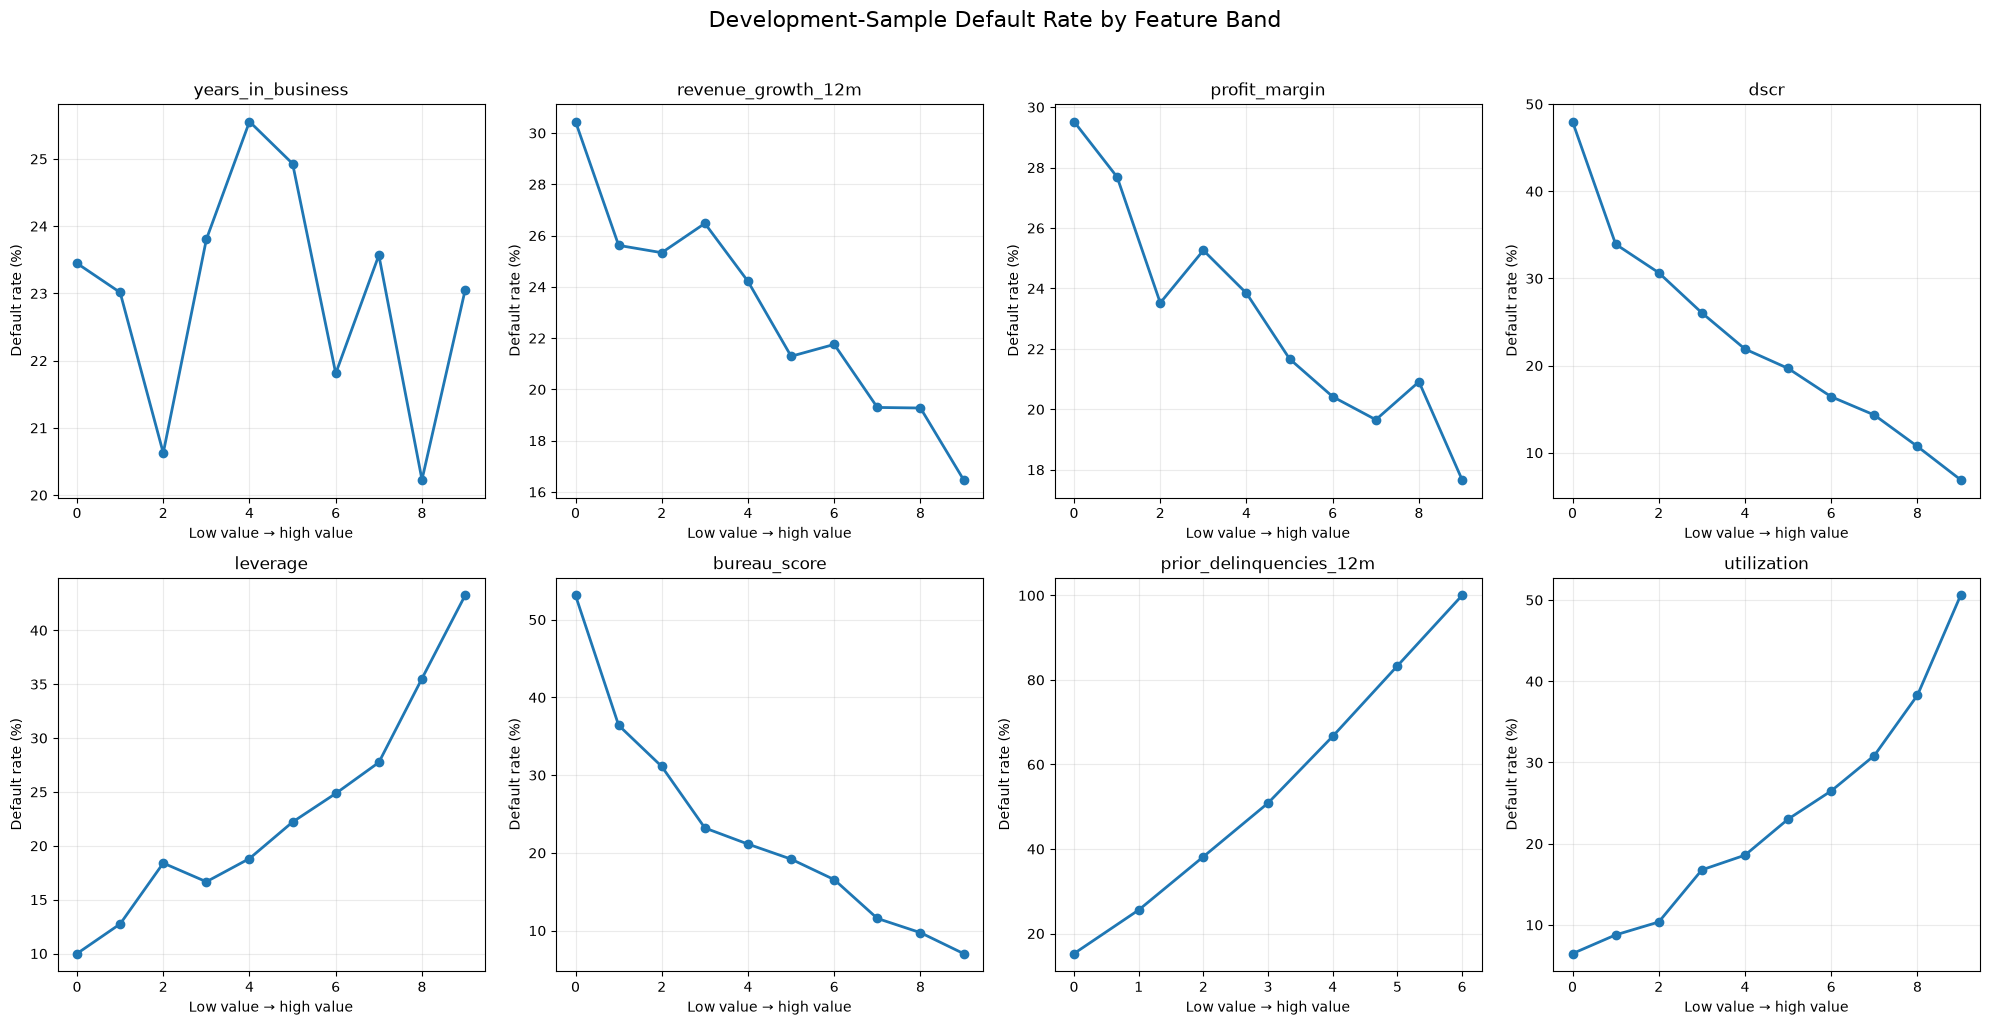


Bad-rate trend: bureau_score


,risk_band,applicants,defaults,bad_rate,average_value
0,"(494.999, 651.0]","1,056",561,53.12%,624.923
1,"(651.0, 674.0]","1,093",398,36.41%,663.888
2,"(674.0, 690.0]","1,022",318,31.12%,682.852
3,"(690.0, 704.0]","1,073",249,23.21%,697.653
4,"(704.0, 716.0]","1,041",220,21.13%,710.570
5,"(716.0, 728.0]","1,021",196,19.20%,722.470
6,"(728.0, 741.0]","1,111",184,16.56%,734.891
7,"(741.0, 755.0]","1,020",118,11.57%,748.448
8,"(755.0, 775.0]","1,027",100,9.74%,764.697
9,"(775.0, 850.0]","1,036",73,7.05%,795.292



Bad-rate trend: dscr


,risk_band,applicants,defaults,bad_rate,average_value
0,"(0.199, 0.92]","1,098",527,48.00%,0.723
1,"(0.92, 1.1]","1,005",341,33.93%,1.021
2,"(1.1, 1.24]","1,070",328,30.65%,1.177
3,"(1.24, 1.36]","1,098",286,26.05%,1.306
4,"(1.36, 1.46]",991,217,21.90%,1.416
5,"(1.46, 1.58]","1,118",220,19.68%,1.526
6,"(1.58, 1.69]","1,041",171,16.43%,1.640
7,"(1.69, 1.82]","1,005",144,14.33%,1.757
8,"(1.82, 2.01]","1,045",112,10.72%,1.911
9,"(2.01, 3.17]","1,029",71,6.90%,2.217



Bad-rate trend: leverage


,risk_band,applicants,defaults,bad_rate,average_value
0,"(0.0189, 0.259]","1,050",105,10.00%,0.172
1,"(0.259, 0.377]","1,051",134,12.75%,0.320
2,"(0.377, 0.477]","1,049",193,18.40%,0.428
3,"(0.477, 0.57]","1,050",175,16.67%,0.525
4,"(0.57, 0.663]","1,052",198,18.82%,0.618
5,"(0.663, 0.757]","1,049",233,22.21%,0.710
6,"(0.757, 0.854]","1,050",261,24.86%,0.803
7,"(0.854, 0.974]","1,049",291,27.74%,0.914
8,"(0.974, 1.121]","1,050",373,35.52%,1.045
9,"(1.121, 1.557]","1,050",454,43.24%,1.253



Bad-rate trend: utilization


,risk_band,applicants,defaults,bad_rate,average_value
0,"(0.0097, 0.18]","1,051",68,6.47%,0.118
1,"(0.18, 0.252]","1,049",92,8.77%,0.217
2,"(0.252, 0.316]","1,052",109,10.36%,0.284
3,"(0.316, 0.377]","1,049",176,16.78%,0.347
4,"(0.377, 0.432]","1,049",195,18.59%,0.405
5,"(0.432, 0.492]","1,051",242,23.03%,0.462
6,"(0.492, 0.555]","1,049",278,26.50%,0.523
7,"(0.555, 0.627]","1,050",324,30.86%,0.590
8,"(0.627, 0.716]","1,050",402,38.29%,0.669
9,"(0.716, 0.984]","1,050",531,50.57%,0.799


In [6]:
import matplotlib.pyplot as plt
risk_direction_features = [
    "years_in_business",
    "revenue_growth_12m",
    "profit_margin",
    "dscr",
    "leverage",
    "bureau_score",
    "prior_delinquencies_12m",
    "utilization"
]

risk_trend_tables = {}

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

for index, feature in enumerate(risk_direction_features):

    analysis_frame = development_sample[[feature, TARGET]].copy()

    # Preserve natural discrete groups for low-cardinality variables
    if analysis_frame[feature].nunique() <= 10:
        analysis_frame["risk_band"] = analysis_frame[feature]
    else:
        analysis_frame["risk_band"] = pd.qcut(
            analysis_frame[feature],
            q=10,
            duplicates="drop"
        )

    trend = (
        analysis_frame
        .groupby("risk_band", observed=True)
        .agg(
            applicants=(TARGET, "size"),
            defaults=(TARGET, "sum"),
            bad_rate=(TARGET, "mean"),
            average_value=(feature, "mean")
        )
        .reset_index()
    )

    trend["feature"] = feature
    risk_trend_tables[feature] = trend

    axes[index].plot(
        range(len(trend)),
        trend["bad_rate"] * 100,
        marker="o",
        linewidth=2
    )

    axes[index].set_title(feature)
    axes[index].set_xlabel("Low value → high value")
    axes[index].set_ylabel("Default rate (%)")
    axes[index].grid(alpha=0.25)

plt.suptitle(
    "Development-Sample Default Rate by Feature Band",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()

# Example detailed tables for four major credit-risk drivers
for feature in [
    "bureau_score",
    "dscr",
    "leverage",
    "utilization"
]:
    print(f"\nBad-rate trend: {feature}")

    display(
        risk_trend_tables[feature][
            ["risk_band", "applicants", "defaults",
             "bad_rate", "average_value"]
        ].style.format({
            "applicants": "{:,.0f}",
            "defaults": "{:,.0f}",
            "bad_rate": "{:.2%}",
            "average_value": "{:,.3f}"
        })
    )

## 5.2 Assess Risk-Direction Monotonicity

Before WOE transformation, we assess whether the observed default rate changes in the
expected direction as each variable increases.

Minor reversals between adjacent preliminary bands can occur because of sampling noise.
These bands are exploratory and are not yet the final scorecard bins.

In [7]:
expected_risk_direction = {
    "years_in_business": "decreasing",
    "revenue_growth_12m": "decreasing",
    "profit_margin": "decreasing",
    "dscr": "decreasing",
    "leverage": "increasing",
    "bureau_score": "decreasing",
    "prior_delinquencies_12m": "increasing",
    "utilization": "increasing",
}

monotonicity_results = []

for feature, expected_direction in expected_risk_direction.items():

    trend = (
        risk_trend_tables[feature]
        .sort_values("average_value")
        .reset_index(drop=True)
    )

    bad_rate_changes = trend["bad_rate"].diff().dropna()

    if expected_direction == "increasing":
        violations = (bad_rate_changes < 0).sum()
    else:
        violations = (bad_rate_changes > 0).sum()

    # Rank correlation between feature value and observed bad rate
    spearman_correlation = (
        trend["average_value"]
        .rank()
        .corr(trend["bad_rate"].rank())
    )

    observed_direction = (
        "increasing"
        if spearman_correlation > 0
        else "decreasing"
        if spearman_correlation < 0
        else "flat"
    )

    monotonicity_results.append(
        {
            "feature": feature,
            "expected_direction": expected_direction,
            "observed_direction": observed_direction,
            "spearman_correlation": spearman_correlation,
            "adjacent_reversals": int(violations),
            "number_of_bands": len(trend),
            "direction_matches": observed_direction == expected_direction,
        }
    )

monotonicity_summary = pd.DataFrame(monotonicity_results)

display(
    monotonicity_summary.style.format(
        {
            "spearman_correlation": "{:.3f}",
            "adjacent_reversals": "{:,.0f}",
            "number_of_bands": "{:,.0f}",
        }
    )
)

,feature,expected_direction,observed_direction,spearman_correlation,adjacent_reversals,number_of_bands,direction_matches
0,years_in_business,decreasing,decreasing,-0.127,4,10,True
1,revenue_growth_12m,decreasing,decreasing,-0.952,2,10,True
2,profit_margin,decreasing,decreasing,-0.927,2,10,True
3,dscr,decreasing,decreasing,-1.000,0,10,True
4,leverage,increasing,increasing,0.988,1,10,True
5,bureau_score,decreasing,decreasing,-1.000,0,10,True
6,prior_delinquencies_12m,increasing,increasing,1.000,0,7,True
7,utilization,increasing,increasing,1.000,0,10,True


In [8]:
print(monotonicity_summary.to_string(index=False))

                feature expected_direction observed_direction  spearman_correlation  adjacent_reversals  number_of_bands  direction_matches
      years_in_business         decreasing         decreasing               -0.1273                   4               10               True
     revenue_growth_12m         decreasing         decreasing               -0.9515                   2               10               True
          profit_margin         decreasing         decreasing               -0.9273                   2               10               True
                   dscr         decreasing         decreasing               -1.0000                   0               10               True
               leverage         increasing         increasing                0.9879                   1               10               True
           bureau_score         decreasing         decreasing               -1.0000                   0               10               True
prior_delinquencies_

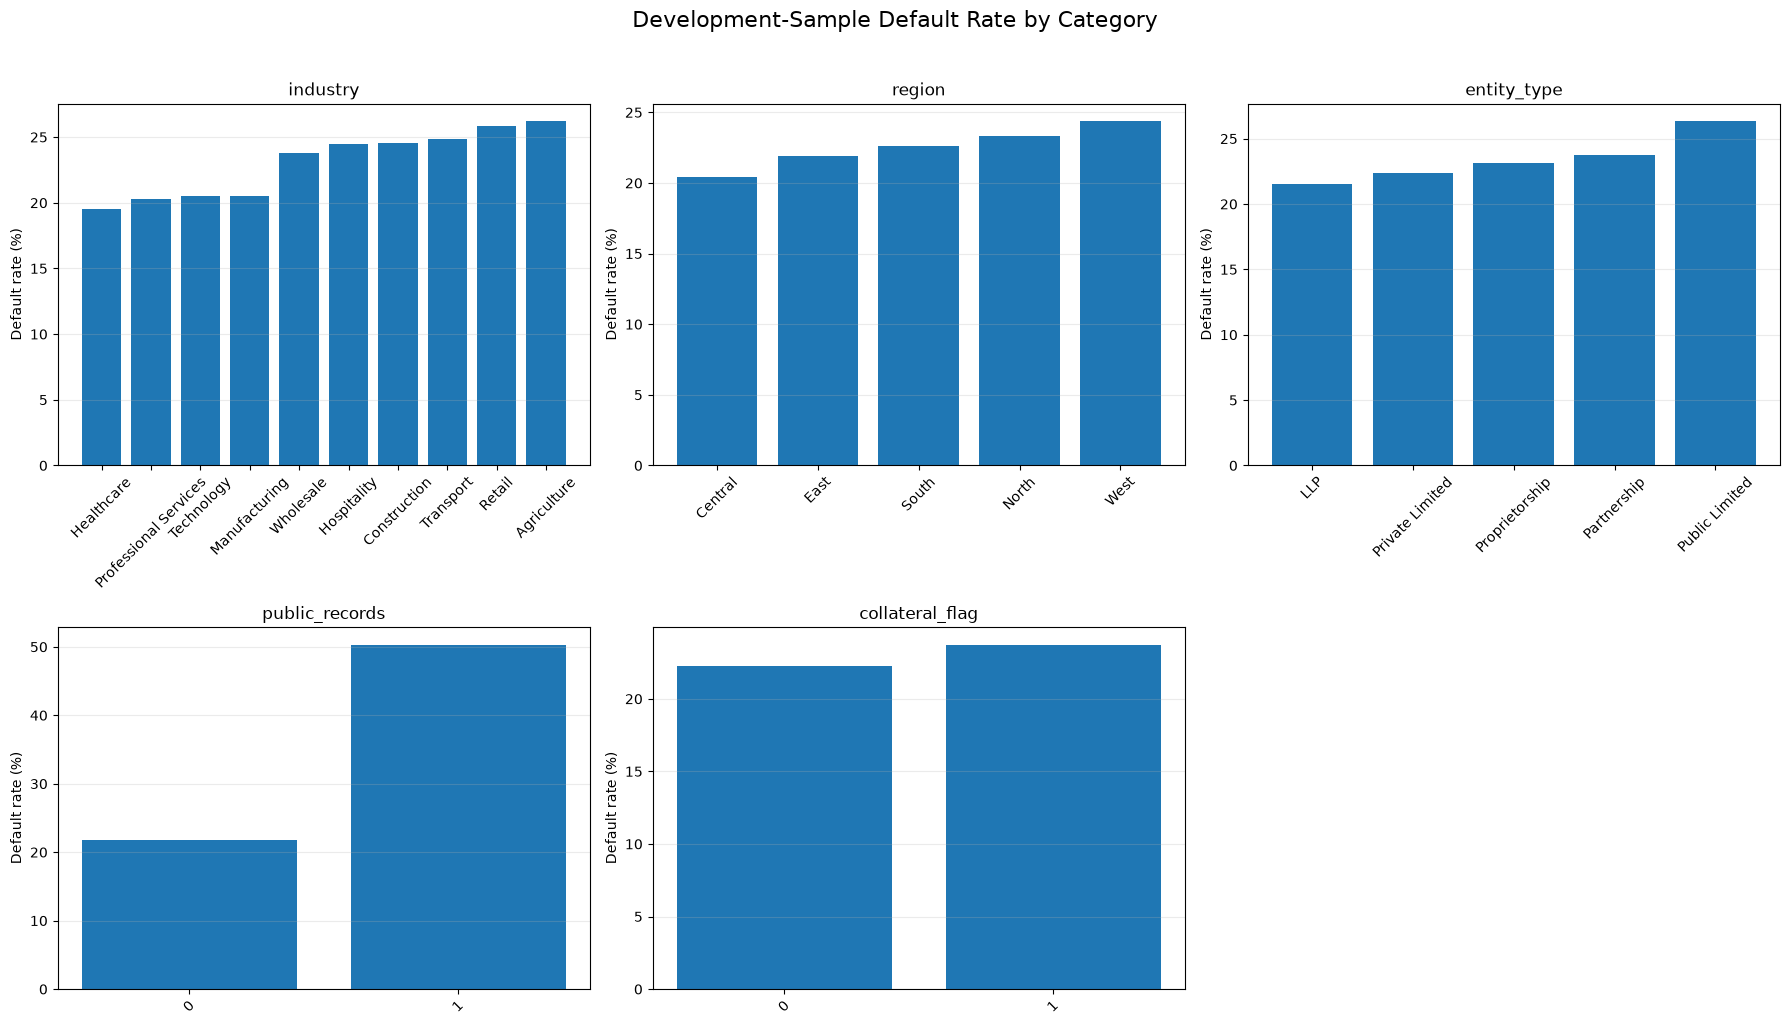


Categorical risk trend: industry


,industry,applicants,defaults,bad_rate,population_share
2,Healthcare,788,154,19.54%,7.50%
5,Professional Services,"1,427",290,20.32%,13.59%
7,Technology,669,137,20.48%,6.37%
4,Manufacturing,"1,522",312,20.50%,14.50%
9,Wholesale,803,191,23.79%,7.65%
3,Hospitality,874,214,24.49%,8.32%
1,Construction,"1,062",261,24.58%,10.11%
8,Transport,"1,043",259,24.83%,9.93%
6,Retail,"1,866",482,25.83%,17.77%
0,Agriculture,446,117,26.23%,4.25%



Categorical risk trend: region


,region,applicants,defaults,bad_rate,population_share
0,Central,504,103,20.44%,4.80%
1,East,"1,919",421,21.94%,18.28%
3,South,"2,618",593,22.65%,24.93%
2,North,"2,889",673,23.30%,27.51%
4,West,"2,570",627,24.40%,24.48%



Categorical risk trend: entity_type


,entity_type,applicants,defaults,bad_rate,population_share
0,LLP,"1,255",270,21.51%,11.95%
2,Private Limited,"2,473",554,22.40%,23.55%
3,Proprietorship,"4,031",933,23.15%,38.39%
1,Partnership,"2,373",563,23.73%,22.60%
4,Public Limited,368,97,26.36%,3.50%



Categorical risk trend: public_records


,public_records,applicants,defaults,bad_rate,population_share
0,0,"10,053","2,192",21.80%,95.74%
1,1,447,225,50.34%,4.26%



Categorical risk trend: collateral_flag


,collateral_flag,applicants,defaults,bad_rate,population_share
0,0,"5,058","1,125",22.24%,48.17%
1,1,"5,442","1,292",23.74%,51.83%


In [9]:
categorical_risk_features = [
    "industry",
    "region",
    "entity_type",
    "public_records",
    "collateral_flag",
]

categorical_risk_tables = {}

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for index, feature in enumerate(categorical_risk_features):

    trend = (
        development_sample
        .groupby(feature, observed=True)
        .agg(
            applicants=(TARGET, "size"),
            defaults=(TARGET, "sum"),
            bad_rate=(TARGET, "mean"),
        )
        .reset_index()
        .sort_values("bad_rate")
    )

    trend["population_share"] = (
        trend["applicants"] / len(development_sample)
    )

    categorical_risk_tables[feature] = trend

    axes[index].bar(
        trend[feature].astype(str),
        trend["bad_rate"] * 100
    )

    axes[index].set_title(feature)
    axes[index].set_ylabel("Default rate (%)")
    axes[index].tick_params(axis="x", rotation=45)
    axes[index].grid(axis="y", alpha=0.25)

# Remove the unused sixth chart
axes[-1].axis("off")

plt.suptitle(
    "Development-Sample Default Rate by Category",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()

for feature in categorical_risk_features:
    print(f"\nCategorical risk trend: {feature}")

    display(
        categorical_risk_tables[feature].style.format(
            {
                "applicants": "{:,.0f}",
                "defaults": "{:,.0f}",
                "bad_rate": "{:.2%}",
                "population_share": "{:.2%}",
            }
        )
    )

## 6.1 Preliminary Categorical WOE and Information Value

WOE convention: ln(distribution of non-defaults / distribution of defaults).

Positive WOE indicates relatively lower risk; negative WOE indicates relatively higher risk.

We calculate WOE and IV using development data only. A smoothing value of 0.5 is added to each category's good and bad counts to prevent undefined logarithms.

These are preliminary category bins, not final approved scorecard bins.

In [10]:
import numpy as np

categorical_woe_tables = {}
categorical_iv_results = []

SMOOTHING = 0.5

for feature in categorical_risk_features:

    table = (
        development_sample
        .groupby(feature, observed=True, dropna=False)
        .agg(
            applicants=(TARGET, "size"),
            bads=(TARGET, "sum"),
        )
        .reset_index()
    )

    table["goods"] = table["applicants"] - table["bads"]
    table["bad_rate"] = table["bads"] / table["applicants"]
    table["population_share"] = (
        table["applicants"] / len(development_sample)
    )

    number_of_bins = len(table)

    table["good_distribution"] = (
        (table["goods"] + SMOOTHING)
        / (table["goods"].sum() + SMOOTHING * number_of_bins)
    )

    table["bad_distribution"] = (
        (table["bads"] + SMOOTHING)
        / (table["bads"].sum() + SMOOTHING * number_of_bins)
    )

    table["woe"] = np.log(
        table["good_distribution"] / table["bad_distribution"]
    )

    table["iv_component"] = (
        table["good_distribution"] - table["bad_distribution"]
    ) * table["woe"]

    assert table["applicants"].sum() == len(development_sample)
    assert np.isfinite(table["woe"]).all()

    categorical_woe_tables[feature] = table

    categorical_iv_results.append({
        "feature": feature,
        "preliminary_iv": table["iv_component"].sum(),
        "number_of_bins": number_of_bins,
        "smallest_bin_share": table["population_share"].min(),
    })

categorical_iv_summary = (
    pd.DataFrame(categorical_iv_results)
    .sort_values("preliminary_iv", ascending=False)
    .reset_index(drop=True)
)

display(
    categorical_iv_summary.style.format({
        "preliminary_iv": "{:.4f}",
        "smallest_bin_share": "{:.2%}",
    })
)

display(
    categorical_woe_tables["public_records"].style.format({
        "bad_rate": "{:.2%}",
        "population_share": "{:.2%}",
        "good_distribution": "{:.4f}",
        "bad_distribution": "{:.4f}",
        "woe": "{:.4f}",
        "iv_component": "{:.4f}",
    })
)

,feature,preliminary_iv,number_of_bins,smallest_bin_share
0,public_records,0.0848,2,4.26%
1,industry,0.0188,10,4.25%
2,region,0.0033,5,4.80%
3,entity_type,0.0028,5,3.50%
4,collateral_flag,0.0018,2,48.17%


,public_records,applicants,bads,goods,bad_rate,population_share,good_distribution,bad_distribution,woe,iv_component
0,0,10053,2192,7861,21.80%,95.74%,0.9725,0.9067,0.0700,0.0046
1,1,447,225,222,50.34%,4.26%,0.0275,0.0933,-1.2203,0.0802


## 6.2 Numeric Pre-binning and Preliminary Information Value

Numeric features are initially divided into up to ten development-sample
quantile bins. Low-cardinality numeric features retain separate value groups.

Bin boundaries are learned from development data only and stored for reuse.
The outer boundaries extend to negative and positive infinity so future
values outside the development range can still be assigned.

These are preliminary bins. We will review small bins and risk-direction
reversals before freezing the final scorecard bins.

WOE convention: ln(distribution of non-defaults / distribution of defaults).

In [11]:
import numpy as np
import pandas as pd

# Exclude binary features already analysed as categorical variables.
numeric_risk_features = [
    feature
    for feature in development_sample.select_dtypes(
        include="number"
    ).columns
    if feature not in [TARGET, "applicant_id"]
    and feature not in categorical_risk_features
]

numeric_bin_edges = {}
numeric_woe_tables = {}
numeric_iv_results = []

SMOOTHING = 0.5

for feature in numeric_risk_features:

    values = development_sample[feature]

    # Our audited synthetic dataset should have complete, finite values.
    assert values.notna().all(), f"Missing values in {feature}"
    assert np.isfinite(values).all(), f"Non-finite values in {feature}"

    unique_values = np.sort(values.unique())

    if len(unique_values) <= 10:
        # Midpoints retain distinct observed values as separate groups,
        # while allowing the same boundaries to be reused later.
        internal_edges = (
            unique_values[:-1]
            + (unique_values[1:] - unique_values[:-1]) / 2
        )
    else:
        _, quantile_edges = pd.qcut(
            values,
            q=10,
            retbins=True,
            duplicates="drop",
        )
        internal_edges = quantile_edges[1:-1]

    edges = np.concatenate(
        ([-np.inf], internal_edges, [np.inf])
    )

    numeric_bin_edges[feature] = edges

    analysis_frame = development_sample[[feature, TARGET]].copy()

    analysis_frame["risk_band"] = pd.cut(
        values,
        bins=edges,
        include_lowest=True,
    )

    assert analysis_frame["risk_band"].notna().all()

    table = (
        analysis_frame
        .groupby("risk_band", observed=True, sort=True)
        .agg(
            applicants=(TARGET, "size"),
            bads=(TARGET, "sum"),
            average_value=(feature, "mean"),
        )
        .reset_index()
    )

    table["goods"] = table["applicants"] - table["bads"]
    table["bad_rate"] = table["bads"] / table["applicants"]
    table["population_share"] = (
        table["applicants"] / len(development_sample)
    )

    number_of_bins = len(table)

    table["good_distribution"] = (
        (table["goods"] + SMOOTHING)
        / (table["goods"].sum() + SMOOTHING * number_of_bins)
    )

    table["bad_distribution"] = (
        (table["bads"] + SMOOTHING)
        / (table["bads"].sum() + SMOOTHING * number_of_bins)
    )

    table["woe"] = np.log(
        table["good_distribution"] / table["bad_distribution"]
    )

    table["iv_component"] = (
        table["good_distribution"] - table["bad_distribution"]
    ) * table["woe"]

    assert table["applicants"].sum() == len(development_sample)
    assert np.isfinite(table["woe"]).all()

    numeric_woe_tables[feature] = table

    numeric_iv_results.append({
        "feature": feature,
        "preliminary_iv": table["iv_component"].sum(),
        "number_of_bins": number_of_bins,
        "smallest_bin_share": table["population_share"].min(),
        "minimum_bads": table["bads"].min(),
        "minimum_goods": table["goods"].min(),
    })

numeric_iv_summary = (
    pd.DataFrame(numeric_iv_results)
    .sort_values("preliminary_iv", ascending=False)
    .reset_index(drop=True)
)

print("Numeric features assessed:", len(numeric_risk_features))

display(
    numeric_iv_summary.style.format({
        "preliminary_iv": "{:.4f}",
        "smallest_bin_share": "{:.2%}",
    })
)

print("\nDetailed delinquency bins:")
display(
    numeric_woe_tables["prior_delinquencies_12m"].style.format({
        "bad_rate": "{:.2%}",
        "population_share": "{:.2%}",
        "average_value": "{:.2f}",
        "good_distribution": "{:.4f}",
        "bad_distribution": "{:.4f}",
        "woe": "{:.4f}",
        "iv_component": "{:.4f}",
    })
)

Numeric features assessed: 15


,feature,preliminary_iv,number_of_bins,smallest_bin_share,minimum_bads,minimum_goods
0,utilization,0.5898,10,9.99%,68,519
1,bureau_score,0.5654,10,9.71%,73,495
2,dscr,0.4508,10,9.44%,71,571
3,prior_delinquencies_12m,0.3001,7,0.01%,1,0
4,leverage,0.2987,10,9.99%,105,596
5,total_debt,0.0651,10,9.99%,152,742
6,current_ratio,0.0581,10,9.57%,167,743
7,revenue_growth_12m,0.0499,10,9.98%,173,731
8,profit_margin,0.0387,10,9.93%,185,740
9,net_income,0.0273,10,9.99%,193,737



Detailed delinquency bins:


,risk_band,applicants,bads,average_value,goods,bad_rate,population_share,good_distribution,bad_distribution,woe,iv_component
0,"(-inf, 0.5]",5341,815,0.00,4526,15.26%,50.87%,0.5598,0.3369,0.5077,0.1131
1,"(0.5, 1.5]",3460,885,1.00,2575,25.58%,32.95%,0.3185,0.3658,-0.1386,0.0066
2,"(1.5, 2.5]",1278,488,2.00,790,38.18%,12.17%,0.0978,0.2018,-0.7249,0.0754
3,"(2.5, 3.5]",342,174,3.00,168,50.88%,3.26%,0.0208,0.0721,-1.2412,0.0636
4,"(3.5, 4.5]",66,44,4.00,22,66.67%,0.63%,0.0028,0.0184,-1.8882,0.0295
5,"(4.5, 5.5]",12,10,5.00,2,83.33%,0.11%,0.0003,0.0043,-2.6413,0.0106
6,"(5.5, inf]",1,1,6.00,0,100.00%,0.01%,0.0001,0.0006,-2.3048,0.0013


## 6.3 Consolidate Sparse Delinquency Bins

The preliminary delinquency groups contain very few applicants at high counts.
We combine prior delinquencies into three groups: zero, one, and two or more.

This retains the distinction between clean history, a single delinquency,
and repeated delinquency while avoiding unstable estimates in sparse tail bins.

We recalculate WOE and IV after merging, using development data only.
The preliminary results remain available for comparison.

In [12]:
# Keep final binning separate from exploratory/preliminary binning.
final_numeric_bin_edges = {}
final_numeric_woe_tables = {}

feature = "prior_delinquencies_12m"

# Integer counts: 0, 1, 2+
edges = np.array([-np.inf, 0.5, 1.5, np.inf])

analysis_frame = development_sample[[feature, TARGET]].copy()

analysis_frame["risk_band"] = pd.cut(
    analysis_frame[feature],
    bins=edges,
    labels=["0", "1", "2+"],
)

table = (
    analysis_frame
    .groupby("risk_band", observed=True, sort=True)
    .agg(
        applicants=(TARGET, "size"),
        bads=(TARGET, "sum"),
    )
    .reset_index()
)

table["goods"] = table["applicants"] - table["bads"]
table["bad_rate"] = table["bads"] / table["applicants"]
table["population_share"] = (
    table["applicants"] / len(development_sample)
)

number_of_bins = len(table)

table["good_distribution"] = (
    (table["goods"] + SMOOTHING)
    / (table["goods"].sum() + SMOOTHING * number_of_bins)
)

table["bad_distribution"] = (
    (table["bads"] + SMOOTHING)
    / (table["bads"].sum() + SMOOTHING * number_of_bins)
)

table["woe"] = np.log(
    table["good_distribution"] / table["bad_distribution"]
)

table["iv_component"] = (
    table["good_distribution"] - table["bad_distribution"]
) * table["woe"]

assert analysis_frame["risk_band"].notna().all()
assert table["applicants"].sum() == len(development_sample)
assert table["population_share"].ge(0.05).all()
assert table["goods"].gt(0).all()
assert table["bads"].gt(0).all()
assert np.isfinite(table["woe"]).all()
assert table["bad_rate"].is_monotonic_increasing

final_numeric_bin_edges[feature] = edges
final_numeric_woe_tables[feature] = table.copy()

preliminary_iv = numeric_woe_tables[feature]["iv_component"].sum()
merged_iv = table["iv_component"].sum()

print(f"Preliminary IV: {preliminary_iv:.4f}")
print(f"Merged IV:      {merged_iv:.4f}")

display(
    table.style.format({
        "bad_rate": "{:.2%}",
        "population_share": "{:.2%}",
        "good_distribution": "{:.4f}",
        "bad_distribution": "{:.4f}",
        "woe": "{:.4f}",
        "iv_component": "{:.4f}",
    })
)

Preliminary IV: 0.3001
Merged IV:      0.2759


,risk_band,applicants,bads,goods,bad_rate,population_share,good_distribution,bad_distribution,woe,iv_component
0,0,5341,815,4526,15.26%,50.87%,0.5599,0.3372,0.5071,0.1129
1,1,3460,885,2575,25.58%,32.95%,0.3186,0.3661,-0.1392,0.0066
2,2+,1699,717,982,42.20%,16.18%,0.1215,0.2967,-0.8925,0.1563


## 6.4 Consolidate Continuous Risk Bins

For selected continuous risk drivers, we start with up to five development-sample
quantile bins and merge neighbouring bins where observed bad rates violate the
expected economic direction.

We also merge bins with fewer than 5% of development applicants or fewer than
20 defaults or non-defaults. These are project-specific development settings.

WOE and IV are recalculated after merging. Final boundaries and WOE estimates
are learned from development data only and will be applied unchanged to validation.

Monotonicity is imposed by this procedure; it is not independent evidence of
predictive strength. Variables remain subject to subsequent model selection.

In [14]:
continuous_directions = {
    "utilization": "increasing",
    "bureau_score": "decreasing",
    "dscr": "decreasing",
    "leverage": "increasing",
    "current_ratio": "decreasing",
    "revenue_growth_12m": "decreasing",
    "profit_margin": "decreasing",
}


def build_numeric_woe_table(data, feature, edges):
    """Calculate development WOE/IV for a supplied set of boundaries."""
    frame = data[[feature, TARGET]].copy()

    frame["risk_band"] = pd.cut(
        frame[feature],
        bins=edges,
        include_lowest=True,
    )

    assert frame["risk_band"].notna().all()

    result = (
        frame.groupby("risk_band", observed=True, sort=True)
        .agg(
            applicants=(TARGET, "size"),
            bads=(TARGET, "sum"),
        )
        .reset_index()
    )

    result["goods"] = result["applicants"] - result["bads"]
    result["bad_rate"] = result["bads"] / result["applicants"]
    result["population_share"] = result["applicants"] / len(data)

    n_bins = len(result)

    result["good_distribution"] = (
        (result["goods"] + SMOOTHING)
        / (result["goods"].sum() + SMOOTHING * n_bins)
    )

    result["bad_distribution"] = (
        (result["bads"] + SMOOTHING)
        / (result["bads"].sum() + SMOOTHING * n_bins)
    )

    result["woe"] = np.log(
        result["good_distribution"] / result["bad_distribution"]
    )

    result["iv_component"] = (
        result["good_distribution"] - result["bad_distribution"]
    ) * result["woe"]

    return result


continuous_binning_results = []

for feature, direction in continuous_directions.items():

    values = development_sample[feature]

    assert values.notna().all()
    assert np.isfinite(values).all()

    _, quantile_edges = pd.qcut(
        values,
        q=5,
        retbins=True,
        duplicates="drop",
    )

    edges = np.concatenate(
        ([-np.inf], quantile_edges[1:-1], [np.inf])
    )

    while True:
        table = build_numeric_woe_table(
            development_sample, feature, edges
        )

        if len(table) == 1:
            break

        # First address insufficiently populated bins.
        small_bins = table.index[
            (table["population_share"] < 0.05)
            | (table["bads"] < 20)
            | (table["goods"] < 20)
        ].tolist()

        if small_bins:
            position = small_bins[0]

            if position == 0:
                boundary_to_remove = 1
            elif position == len(table) - 1:
                boundary_to_remove = position
            else:
                current_rate = table.loc[position, "bad_rate"]

                left_gap = abs(
                    current_rate - table.loc[position - 1, "bad_rate"]
                )
                right_gap = abs(
                    current_rate - table.loc[position + 1, "bad_rate"]
                )

                boundary_to_remove = (
                    position if left_gap <= right_gap else position + 1
                )

        else:
            changes = table["bad_rate"].diff().to_numpy()[1:]

            reversals = np.flatnonzero(
                changes < -1e-12
                if direction == "increasing"
                else changes > 1e-12
            )

            if len(reversals) == 0:
                break

            # Merge the first adjacent pair that reverses direction.
            boundary_to_remove = int(reversals[0]) + 1

        edges = np.delete(edges, boundary_to_remove)

    assert table["applicants"].sum() == len(development_sample)
    assert np.isfinite(table["woe"]).all()

    changes = table["bad_rate"].diff().dropna()

    monotonic = (
        changes.ge(-1e-12).all()
        if direction == "increasing"
        else changes.le(1e-12).all()
    )

    assert monotonic

    final_numeric_bin_edges[feature] = edges.copy()
    final_numeric_woe_tables[feature] = table.copy()

    continuous_binning_results.append({
        "feature": feature,
        "direction": direction,
        "final_bins": len(table),
        "final_iv": table["iv_component"].sum(),
        "smallest_bin_share": table["population_share"].min(),
        "monotonic": bool(monotonic),
    })

continuous_binning_summary = (
    pd.DataFrame(continuous_binning_results)
    .sort_values("final_iv", ascending=False)
    .reset_index(drop=True)
)

display(
    continuous_binning_summary.style.format({
        "final_iv": "{:.4f}",
        "smallest_bin_share": "{:.2%}",
    })
)

print("\nFinal DSCR bins:")
display(
    final_numeric_woe_tables["dscr"].style.format({
        "bad_rate": "{:.2%}",
        "population_share": "{:.2%}",
        "good_distribution": "{:.4f}",
        "bad_distribution": "{:.4f}",
        "woe": "{:.4f}",
        "iv_component": "{:.4f}",
    })
)

,feature,direction,final_bins,final_iv,smallest_bin_share,monotonic
0,utilization,increasing,5,0.5514,19.99%,True
1,bureau_score,decreasing,5,0.5138,19.64%,True
2,dscr,decreasing,5,0.4164,19.49%,True
3,leverage,increasing,5,0.2858,19.99%,True
4,current_ratio,decreasing,5,0.0528,19.62%,True
5,revenue_growth_12m,decreasing,5,0.0426,19.98%,True
6,profit_margin,decreasing,5,0.0350,19.99%,True



Final DSCR bins:


,risk_band,applicants,bads,goods,bad_rate,population_share,good_distribution,bad_distribution,woe,iv_component
0,"(-inf, 1.1]",2103,868,1235,41.27%,20.03%,0.1528,0.3590,-0.8540,0.1761
1,"(1.1, 1.36]",2168,614,1554,28.32%,20.65%,0.1923,0.2540,-0.2784,0.0172
2,"(1.36, 1.58]",2109,437,1672,20.72%,20.09%,0.2069,0.1808,0.1345,0.0035
3,"(1.58, 1.82]",2046,315,1731,15.40%,19.49%,0.2141,0.1304,0.4961,0.0415
4,"(1.82, inf]",2074,183,1891,8.82%,19.75%,0.2339,0.0758,1.1264,0.1781


## 7. Create Development and Validation WOE Inputs

The initial model candidates comprise seven continuous risk drivers,
prior delinquency groups, and public records.

Numeric bin boundaries and WOE values are fitted on development data only.
Validation applicants are assigned to these same bins and receive the
development WOE values. Validation outcomes are not used in this transformation.

Applicant IDs and the default target are excluded from model inputs.
This is a provisional candidate set, subject to multicollinearity and
coefficient checks before final model selection.

In [16]:
numeric_model_candidates = [
    "utilization",
    "bureau_score",
    "dscr",
    "leverage",
    "current_ratio",
    "revenue_growth_12m",
    "profit_margin",
    "prior_delinquencies_12m",
]

model_candidates = numeric_model_candidates + ["public_records"]


def transform_to_woe(data):
    """Apply stored development bins and WOE values without refitting."""
    transformed = pd.DataFrame(index=data.index)

    for feature in numeric_model_candidates:

        edges = final_numeric_bin_edges[feature]
        woe_table = final_numeric_woe_tables[feature]

        # Integer codes avoid matching rounded interval text.
        bin_codes = pd.cut(
            data[feature],
            bins=edges,
            labels=False,
            include_lowest=True,
        )

        if bin_codes.isna().any():
            raise ValueError(
                f"Missing or unassigned values in {feature}"
            )

        # Stored tables are ordered from the lowest to highest bin.
        assert len(woe_table) == len(edges) - 1

        transformed[feature] = (
            woe_table["woe"]
            .to_numpy()[bin_codes.to_numpy(dtype=int)]
        )

    public_record_mapping = (
        categorical_woe_tables["public_records"]
        .set_index("public_records")["woe"]
        .to_dict()
    )

    transformed["public_records"] = (
        data["public_records"].map(public_record_mapping)
    )

    if not np.isfinite(transformed.to_numpy()).all():
        raise ValueError(
            "WOE inputs contain missing, unknown, or non-finite values."
        )

    return transformed[model_candidates]


X_dev_woe = transform_to_woe(development_sample)
X_val_woe = transform_to_woe(validation_sample)

y_dev = development_sample[TARGET].astype(int).copy()
y_val = validation_sample[TARGET].astype(int).copy()

assert X_dev_woe.index.equals(y_dev.index)
assert X_val_woe.index.equals(y_val.index)
assert X_dev_woe.columns.equals(X_val_woe.columns)
assert TARGET not in X_dev_woe.columns
assert "applicant_id" not in X_dev_woe.columns

print("Development WOE shape:", X_dev_woe.shape)
print("Validation WOE shape:", X_val_woe.shape)
print("WOE transformation checks passed.")

display(X_dev_woe.head())

Development WOE shape: (10500, 9)
Validation WOE shape: (4500, 9)
WOE transformation checks passed.


,utilization,bureau_score,dscr,leverage,current_ratio,revenue_growth_12m,profit_margin,prior_delinquencies_12m,public_records
0,-0.2960,-0.2157,0.1345,0.8446,-0.1308,0.3173,-0.2924,-0.1392,0.0700
1,0.6439,-0.9908,0.4961,0.1471,0.0682,0.1465,0.1765,-0.8925,0.0700
2,-0.2960,-0.9908,1.1264,0.8446,0.0682,0.0152,-0.0759,-0.8925,0.0700
3,-0.9828,-0.9908,1.1264,0.3408,0.1878,0.3173,0.2235,-0.1392,0.0700
4,0.1291,-0.9908,0.1345,-0.1766,-0.1308,-0.1562,0.1765,-0.1392,0.0700


## 8. Multicollinearity Checks

We assess correlation and variance inflation factors (VIF) on the
development-sample WOE inputs.

Absolute pairwise correlation of 0.70 or higher and VIF above 5 are
review flags for this project, not automatic exclusion rules.

VIF is calculated with an intercept. Validation data is not used
to select variables.

In [18]:
%pip install statsmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 28.7 MB/s  0:00:00m0:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [statsmodels] [statsmodels]

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [19]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Confirm that no candidate is constant.
constant_features = X_dev_woe.columns[
    X_dev_woe.nunique() <= 1
].tolist()

assert not constant_features, (
    f"Constant WOE features require review: {constant_features}"
)

# 1. Pairwise correlation
woe_correlation = X_dev_woe.corr()

correlation_pairs = []

for i, feature_1 in enumerate(X_dev_woe.columns):
    for feature_2 in X_dev_woe.columns[i + 1:]:
        correlation = woe_correlation.loc[feature_1, feature_2]

        correlation_pairs.append({
            "feature_1": feature_1,
            "feature_2": feature_2,
            "correlation": correlation,
            "absolute_correlation": abs(correlation),
        })

correlation_summary = (
    pd.DataFrame(correlation_pairs)
    .sort_values("absolute_correlation", ascending=False)
    .reset_index(drop=True)
)

print("Ten most correlated WOE feature pairs:")
display(
    correlation_summary.head(10).style.format({
        "correlation": "{:.3f}",
        "absolute_correlation": "{:.3f}",
    })
)

# 2. VIF, including an intercept in the auxiliary regressions
vif_inputs = sm.add_constant(
    X_dev_woe.astype(float),
    has_constant="add",
)

vif_summary = pd.DataFrame([
    {
        "feature": feature,
        "vif": variance_inflation_factor(
            vif_inputs.to_numpy(),
            position,
        ),
    }
    for position, feature in enumerate(vif_inputs.columns)
    if feature != "const"
])

vif_summary = (
    vif_summary
    .sort_values("vif", ascending=False)
    .reset_index(drop=True)
)

vif_summary["review_required"] = vif_summary["vif"] > 5

print("\nVIF results:")
display(vif_summary.style.format({"vif": "{:.3f}"}))

print(
    "\nPairs with absolute correlation >= 0.70:",
    int(correlation_summary["absolute_correlation"].ge(0.70).sum()),
)
print(
    "Features with VIF > 5:",
    int(vif_summary["review_required"].sum()),
)

Ten most correlated WOE feature pairs:


,feature_1,feature_2,correlation,absolute_correlation
0,utilization,bureau_score,0.588,0.588
1,bureau_score,prior_delinquencies_12m,0.445,0.445
2,dscr,leverage,0.247,0.247
3,utilization,prior_delinquencies_12m,0.247,0.247
4,bureau_score,public_records,0.235,0.235
5,dscr,profit_margin,0.205,0.205
6,leverage,current_ratio,0.172,0.172
7,current_ratio,profit_margin,0.144,0.144
8,dscr,revenue_growth_12m,0.114,0.114
9,prior_delinquencies_12m,public_records,0.111,0.111



VIF results:


,feature,vif,review_required
0,bureau_score,1.898,False
1,utilization,1.552,False
2,prior_delinquencies_12m,1.256,False
3,dscr,1.130,False
4,leverage,1.104,False
5,public_records,1.076,False
6,profit_margin,1.072,False
7,current_ratio,1.054,False
8,revenue_growth_12m,1.015,False



Pairs with absolute correlation >= 0.70: 0
Features with VIF > 5: 0


## 9. Fit the Initial WOE Logistic Scorecard

We fit an unregularized logistic regression using the nine candidate WOE
features and the development sample only.

Target: default_12m = 1 indicates default.

WOE convention: ln(good distribution / bad distribution).
Therefore, negative feature coefficients are generally expected:
higher WOE should reduce predicted default risk.

We review convergence, coefficient signs, confidence intervals and p-values.
P-values are exploratory because binning and candidate selection have already
used development outcomes. Variables are not removed automatically.

In [20]:
import statsmodels.api as sm

# Preserve the candidate order for future prediction.
initial_model_features = X_dev_woe.columns.tolist()

X_dev_logit = sm.add_constant(
    X_dev_woe[initial_model_features].astype(float),
    has_constant="add",
)

initial_logit_model = sm.Logit(
    y_dev,
    X_dev_logit,
).fit(
    method="newton",
    maxiter=200,
    disp=False,
)

converged = initial_logit_model.mle_retvals["converged"]

print("Model converged:", converged)
print("Development observations:", int(initial_logit_model.nobs))
print("Number of candidate features:", len(initial_model_features))

assert converged, "Model did not converge; review before proceeding."

confidence_intervals = initial_logit_model.conf_int()

coefficient_summary = pd.DataFrame({
    "coefficient": initial_logit_model.params,
    "standard_error": initial_logit_model.bse,
    "p_value": initial_logit_model.pvalues,
    "ci_lower": confidence_intervals[0],
    "ci_upper": confidence_intervals[1],
})

coefficient_summary.index.name = "feature"
coefficient_summary = coefficient_summary.reset_index()

coefficient_summary["sign_review"] = [
    "Intercept"
    if feature == "const"
    else "Expected negative"
    if coefficient < 0
    else "Review non-negative"
    for feature, coefficient in zip(
        coefficient_summary["feature"],
        coefficient_summary["coefficient"],
    )
]

coefficient_summary["p_value_above_0_05"] = (
    coefficient_summary["p_value"] > 0.05
)

display(
    coefficient_summary.style.format({
        "coefficient": "{:.4f}",
        "standard_error": "{:.4f}",
        "p_value": "{:.4g}",
        "ci_lower": "{:.4f}",
        "ci_upper": "{:.4f}",
    })
)

print(
    "\nDevelopment AIC:",
    round(initial_logit_model.aic, 2),
)

Model converged: True
Development observations: 10500
Number of candidate features: 9


,feature,coefficient,standard_error,p_value,ci_lower,ci_upper,sign_review,p_value_above_0_05
0,const,-1.2195,0.0280,0,-1.2744,-1.1646,Intercept,False
1,utilization,-0.8984,0.0447,7.995e-90,-0.9860,-0.8108,Expected negative,False
2,bureau_score,-0.4074,0.0492,1.26e-16,-0.5038,-0.3109,Expected negative,False
3,dscr,-0.9808,0.0453,3.805e-104,-1.0695,-0.8921,Expected negative,False
4,leverage,-0.8791,0.0525,6.172e-63,-0.9820,-0.7762,Expected negative,False
5,current_ratio,-0.7561,0.1197,2.641e-10,-0.9906,-0.5215,Expected negative,False
6,revenue_growth_12m,-0.8630,0.1317,5.638e-11,-1.1212,-0.6049,Expected negative,False
7,profit_margin,-0.3522,0.1476,0.01703,-0.6415,-0.0629,Expected negative,False
8,prior_delinquencies_12m,-0.5382,0.0547,7.796e-23,-0.6454,-0.4310,Expected negative,False
9,public_records,-0.8096,0.0929,2.837e-18,-0.9916,-0.6276,Expected negative,False



Development AIC: 8662.22


## 10. Evaluate Discrimination and Probability Accuracy

We evaluate the fixed nine-variable model on development and held-out validation.

AUC, Gini and KS measure discrimination. KS is calculated from ROC thresholds,
keeping tied predictions together.

Mean predicted PD is compared with observed default rate as an aggregate
calibration check. Brier score and log loss assess probability accuracy.

Validation outcomes are used for evaluation, not to refit this model.
Development performance is in-sample and may be optimistic.

In [21]:
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    brier_score_loss,
    log_loss,
)

# Retain the reviewed model and feature order.
scorecard_model = initial_logit_model
selected_features = initial_model_features.copy()

# Apply the same design matrix structure to validation.
X_val_logit = sm.add_constant(
    X_val_woe[selected_features].astype(float),
    has_constant="add",
)

X_val_logit = X_val_logit[scorecard_model.params.index]

pd_dev = scorecard_model.predict(X_dev_logit)
pd_val = scorecard_model.predict(X_val_logit)

assert np.isfinite(pd_dev).all()
assert np.isfinite(pd_val).all()
assert pd_dev.between(0, 1).all()
assert pd_val.between(0, 1).all()


def evaluate_scorecard(sample_name, actual, predicted):
    auc = roc_auc_score(actual, predicted)
    fpr, tpr, _ = roc_curve(
        actual,
        predicted,
        drop_intermediate=False,
    )

    return {
        "sample": sample_name,
        "applicants": len(actual),
        "defaults": int(actual.sum()),
        "observed_default_rate": actual.mean(),
        "average_predicted_pd": predicted.mean(),
        "pd_minus_observed": predicted.mean() - actual.mean(),
        "auc": auc,
        "gini": 2 * auc - 1,
        "ks": np.max(np.abs(tpr - fpr)),
        "brier_score": brier_score_loss(actual, predicted),
        "log_loss": log_loss(actual, predicted),
    }


performance_summary = pd.DataFrame([
    evaluate_scorecard("Development", y_dev, pd_dev),
    evaluate_scorecard("Validation", y_val, pd_val),
])

display(
    performance_summary.style.format({
        "applicants": "{:,.0f}",
        "defaults": "{:,.0f}",
        "observed_default_rate": "{:.2%}",
        "average_predicted_pd": "{:.2%}",
        "pd_minus_observed": "{:+.2%}",
        "auc": "{:.4f}",
        "gini": "{:.4f}",
        "ks": "{:.2%}",
        "brier_score": "{:.4f}",
        "log_loss": "{:.4f}",
    })
)

auc_gap = (
    performance_summary.loc[0, "auc"]
    - performance_summary.loc[1, "auc"]
)

print(f"Development minus validation AUC: {auc_gap:+.4f}")

# Compare against a constant PD estimated from development only.
baseline_pd = np.full(len(y_val), y_dev.mean())

print(
    "Validation Brier — constant-PD baseline:",
    f"{brier_score_loss(y_val, baseline_pd):.4f}",
)
print(
    "Validation Brier — scorecard:",
    f"{brier_score_loss(y_val, pd_val):.4f}",
)

,sample,applicants,defaults,observed_default_rate,average_predicted_pd,pd_minus_observed,auc,gini,ks,brier_score,log_loss
0,Development,"10,500","2,417",23.02%,23.02%,+0.00%,0.8211,0.6422,48.33%,0.1317,0.4115
1,Validation,"4,500","1,036",23.02%,22.57%,-0.45%,0.8250,0.6499,49.48%,0.1296,0.4072


Development minus validation AUC: -0.0039
Validation Brier — constant-PD baseline: 0.1772
Validation Brier — scorecard: 0.1296


## 11. Risk-Band Ordering and Calibration

We define ten risk bands using development predicted-PD quantiles.
Band 1 represents the lowest predicted risk and Band 10 the highest.

The same development cut-offs are applied unchanged to validation.
We compare observed default rates with average predicted PD within each band.

Minor observed bad-rate reversals may occur through sampling variation.
Validation bands will not be adjusted to force monotonicity.


Development risk bands:


,risk_band,applicants,defaults,observed_bad_rate,average_predicted_pd,population_share,observed_minus_predicted
0,1,"1,050",20,1.90%,1.67%,10.00%,+0.24%
1,2,"1,050",35,3.33%,3.75%,10.00%,-0.42%
2,3,"1,050",61,5.81%,6.24%,10.00%,-0.43%
3,4,"1,050",97,9.24%,9.32%,10.00%,-0.08%
4,5,"1,050",133,12.67%,13.20%,10.00%,-0.53%
5,6,"1,050",212,20.19%,18.19%,10.00%,+2.00%
6,7,"1,050",250,23.81%,24.79%,10.00%,-0.98%
7,8,"1,051",376,35.78%,34.46%,10.01%,+1.32%
8,9,"1,049",498,47.47%,47.77%,9.99%,-0.30%
9,10,"1,050",735,70.00%,70.82%,10.00%,-0.82%


Observed bad-rate reversals: 0

Validation risk bands:


,risk_band,applicants,defaults,observed_bad_rate,average_predicted_pd,population_share,observed_minus_predicted
0,1,445,6,1.35%,1.68%,9.89%,-0.33%
1,2,487,20,4.11%,3.82%,10.82%,+0.29%
2,3,477,30,6.29%,6.23%,10.60%,+0.06%
3,4,465,45,9.68%,9.38%,10.33%,+0.29%
4,5,456,61,13.38%,13.09%,10.13%,+0.29%
5,6,419,77,18.38%,18.29%,9.31%,+0.08%
6,7,427,108,25.29%,24.93%,9.49%,+0.36%
7,8,445,155,34.83%,34.18%,9.89%,+0.65%
8,9,443,222,50.11%,48.04%,9.84%,+2.08%
9,10,436,312,71.56%,70.82%,9.69%,+0.74%


Observed bad-rate reversals: 0


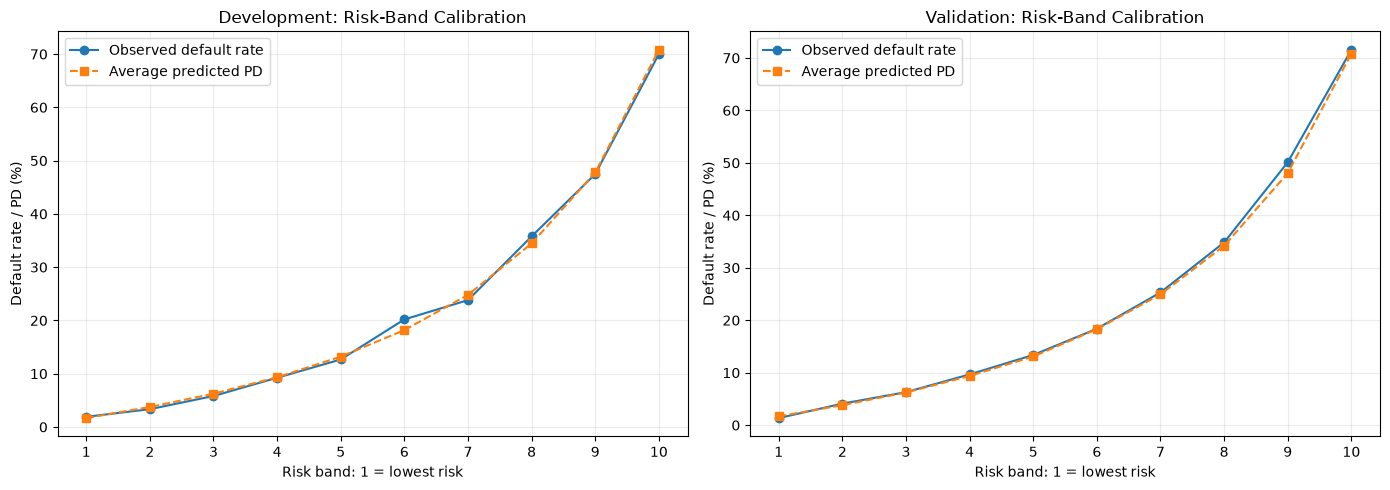

In [22]:
# Learn risk-band cut-offs from development predictions only.
_, pd_quantile_edges = pd.qcut(
    pd_dev,
    q=10,
    retbins=True,
    duplicates="drop",
)

risk_band_edges = np.concatenate(
    ([-np.inf], pd_quantile_edges[1:-1], [np.inf])
)

risk_band_labels = list(range(1, len(risk_band_edges)))


def create_risk_band_table(actual, predicted):
    assert actual.index.equals(predicted.index)

    frame = pd.DataFrame({
        "actual": actual,
        "predicted_pd": predicted,
    })

    frame["risk_band"] = pd.cut(
        frame["predicted_pd"],
        bins=risk_band_edges,
        labels=risk_band_labels,
        include_lowest=True,
    )

    assert frame["risk_band"].notna().all()

    table = (
        frame.groupby("risk_band", observed=False, sort=True)
        .agg(
            applicants=("actual", "size"),
            defaults=("actual", "sum"),
            observed_bad_rate=("actual", "mean"),
            average_predicted_pd=("predicted_pd", "mean"),
        )
        .reset_index()
    )

    table["population_share"] = (
        table["applicants"] / len(frame)
    )

    # Positive gap means the model underpredicts the observed rate.
    table["observed_minus_predicted"] = (
        table["observed_bad_rate"] - table["average_predicted_pd"]
    )

    assert table["applicants"].sum() == len(frame)

    return table


development_band_table = create_risk_band_table(y_dev, pd_dev)
validation_band_table = create_risk_band_table(y_val, pd_val)

band_format = {
    "applicants": "{:,.0f}",
    "defaults": "{:,.0f}",
    "observed_bad_rate": "{:.2%}",
    "average_predicted_pd": "{:.2%}",
    "population_share": "{:.2%}",
    "observed_minus_predicted": "{:+.2%}",
}

for name, table in [
    ("Development", development_band_table),
    ("Validation", validation_band_table),
]:
    print(f"\n{name} risk bands:")
    display(table.style.format(band_format))

    populated_bands = table.loc[table["applicants"] > 0]

    reversals = (
        populated_bands["observed_bad_rate"]
        .diff()
        .lt(0)
        .sum()
    )

    print("Observed bad-rate reversals:", int(reversals))


# Compare observed and predicted rates in the same bands.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, name, table in zip(
    axes,
    ["Development", "Validation"],
    [development_band_table, validation_band_table],
):
    ax.plot(
        table["risk_band"].astype(int),
        table["observed_bad_rate"] * 100,
        marker="o",
        label="Observed default rate",
    )

    ax.plot(
        table["risk_band"].astype(int),
        table["average_predicted_pd"] * 100,
        marker="s",
        linestyle="--",
        label="Average predicted PD",
    )

    ax.set_title(f"{name}: Risk-Band Calibration")
    ax.set_xlabel("Risk band: 1 = lowest risk")
    ax.set_ylabel("Default rate / PD (%)")
    ax.set_xticks(risk_band_labels)
    ax.grid(alpha=0.25)
    ax.legend()

plt.tight_layout()
plt.show()

## 12. Population Stability Index

We compare development and validation applicant proportions using the same
development-defined predicted-PD bands.

PSI = sum((validation share - development share)
          * ln(validation share / development share)).

A small pseudocount handles empty bands. Low PSI indicates similar risk-score
distributions across these samples; it does not establish stability over time,
because this is a random split of one synthetic population.

In [23]:
# Align all bands explicitly before comparing counts.
dev_band_counts = (
    development_band_table
    .set_index("risk_band")["applicants"]
    .reindex(risk_band_labels, fill_value=0)
    .astype(float)
)

val_band_counts = (
    validation_band_table
    .set_index("risk_band")["applicants"]
    .reindex(risk_band_labels, fill_value=0)
    .astype(float)
)

assert dev_band_counts.sum() == len(y_dev)
assert val_band_counts.sum() == len(y_val)

psi_table = pd.DataFrame({
    "development_count": dev_band_counts,
    "validation_count": val_band_counts,
})

psi_table.index.name = "risk_band"

# Actual proportions for reporting.
psi_table["development_share"] = (
    dev_band_counts / dev_band_counts.sum()
)

psi_table["validation_share"] = (
    val_band_counts / val_band_counts.sum()
)

# Smoothed proportions used only in the PSI calculation.
PSI_PSEUDOCOUNT = 0.5
number_of_bands = len(psi_table)

dev_share_smoothed = (
    (dev_band_counts + PSI_PSEUDOCOUNT)
    / (
        dev_band_counts.sum()
        + PSI_PSEUDOCOUNT * number_of_bands
    )
)

val_share_smoothed = (
    (val_band_counts + PSI_PSEUDOCOUNT)
    / (
        val_band_counts.sum()
        + PSI_PSEUDOCOUNT * number_of_bands
    )
)

psi_table["psi_component"] = (
    val_share_smoothed - dev_share_smoothed
) * np.log(val_share_smoothed / dev_share_smoothed)

score_psi = psi_table["psi_component"].sum()

display(
    psi_table.reset_index().style.format({
        "development_count": "{:,.0f}",
        "validation_count": "{:,.0f}",
        "development_share": "{:.2%}",
        "validation_share": "{:.2%}",
        "psi_component": "{:.6f}",
    })
)

print(f"Development versus validation score PSI: {score_psi:.6f}")

,risk_band,development_count,validation_count,development_share,validation_share,psi_component
0,1,"1,050",445,10.00%,9.89%,0.000012
1,2,"1,050",487,10.00%,10.82%,0.000648
2,3,"1,050",477,10.00%,10.60%,0.000349
3,4,"1,050",465,10.00%,10.33%,0.000109
4,5,"1,050",456,10.00%,10.13%,0.000018
5,6,"1,050",419,10.00%,9.31%,0.000491
6,7,"1,050",427,10.00%,9.49%,0.000268
7,8,"1,051",445,10.01%,9.89%,0.000015
8,9,"1,049",443,9.99%,9.84%,0.000021
9,10,"1,050",436,10.00%,9.69%,0.000098


Development versus validation score PSI: 0.002028


## 13. Convert the Logistic Model into Scorecard Points

We use a reference score of 600 at good-to-bad odds of 20:1,
with 50 points to double the odds (PDO).

Factor = PDO / ln(2)
Offset = Reference score - Factor × ln(Reference good-to-bad odds)

Score = Offset - Factor × logit(PD)

The score is additive:
Base points = Offset - Factor × intercept
Feature points = -Factor × coefficient × WOE

These are project-defined points, not a bureau score.
No clipping is applied. Unrounded points preserve the exact model relationship.

In [24]:
REFERENCE_SCORE = 600
REFERENCE_GOOD_BAD_ODDS = 20
PDO = 50

SCORE_FACTOR = PDO / np.log(2)
SCORE_OFFSET = (
    REFERENCE_SCORE
    - SCORE_FACTOR * np.log(REFERENCE_GOOD_BAD_ODDS)
)

base_points = (
    SCORE_OFFSET
    - SCORE_FACTOR * scorecard_model.params["const"]
)


def calculate_score_points(woe_inputs):
    """Return exact total scores and individual feature contributions."""
    feature_points = (
        woe_inputs[selected_features]
        .mul(scorecard_model.params[selected_features], axis="columns")
        .mul(-SCORE_FACTOR)
    )

    total_score = base_points + feature_points.sum(axis=1)

    return total_score, feature_points


score_dev, points_dev = calculate_score_points(X_dev_woe)
score_val, points_val = calculate_score_points(X_val_woe)

# Verify that scores recover the original predicted probabilities.
recovered_pd_val = 1 / (
    1 + np.exp((score_val - SCORE_OFFSET) / SCORE_FACTOR)
)

assert np.allclose(
    recovered_pd_val,
    pd_val,
    atol=1e-12,
    rtol=1e-10,
)

# Verify the chosen reference scale.
reference_pd = 1 / (1 + REFERENCE_GOOD_BAD_ODDS)

reference_score_check = (
    SCORE_OFFSET
    + SCORE_FACTOR * np.log((1 - reference_pd) / reference_pd)
)

assert np.isclose(reference_score_check, REFERENCE_SCORE)

# Build the bin-level additive points table.
scorecard_rows = []

for feature in selected_features:

    if feature in final_numeric_woe_tables:
        bin_table = final_numeric_woe_tables[feature]
        bin_column = "risk_band"
    else:
        bin_table = categorical_woe_tables[feature]
        bin_column = feature

    coefficient = scorecard_model.params[feature]

    for _, row in bin_table.iterrows():
        scorecard_rows.append({
            "feature": feature,
            "bin": str(row[bin_column]),
            "woe": row["woe"],
            "coefficient": coefficient,
            "feature_points": (
                -SCORE_FACTOR * coefficient * row["woe"]
            ),
        })

scorecard_points_table = pd.DataFrame(scorecard_rows)

print(f"Factor: {SCORE_FACTOR:.4f}")
print(f"Offset: {SCORE_OFFSET:.4f}")
print(f"Base points: {base_points:.4f}")
print("Score-to-PD reconciliation passed.")

print("\nBin-level scorecard points:")
display(
    scorecard_points_table.style.format({
        "woe": "{:.4f}",
        "coefficient": "{:.4f}",
        "feature_points": "{:.2f}",
    })
)

# Show the first five validation applicants.
validation_score_preview = pd.DataFrame({
    "applicant_id": validation_sample["applicant_id"],
    "predicted_pd": pd_val,
    "exact_score": score_val,
    "display_score": score_val.round().astype(int),
})

print("\nValidation scoring examples:")
display(
    validation_score_preview.head().style.format({
        "predicted_pd": "{:.2%}",
        "exact_score": "{:.2f}",
    })
)

print("\nScore distributions:")
display(
    pd.DataFrame({
        "Development": score_dev.describe(),
        "Validation": score_val.describe(),
    }).round(2)
)

Factor: 72.1348
Offset: 383.9036
Base points: 471.8749
Score-to-PD reconciliation passed.

Bin-level scorecard points:


,feature,bin,woe,coefficient,feature_points
0,utilization,"(-inf, 0.252]",1.2859,-0.8984,83.33
1,utilization,"(0.252, 0.377]",0.6439,-0.8984,41.73
2,utilization,"(0.377, 0.492]",0.1291,-0.8984,8.37
3,utilization,"(0.492, 0.627]",-0.2960,-0.8984,-19.19
4,utilization,"(0.627, inf]",-0.9828,-0.8984,-63.69
5,bureau_score,"(-inf, 674.0]",-0.9908,-0.4074,-29.11
6,bureau_score,"(674.0, 704.0]",-0.2157,-0.4074,-6.34
7,bureau_score,"(704.0, 728.0]",0.1680,-0.4074,4.94
8,bureau_score,"(728.0, 755.0]",0.5932,-0.4074,17.43
9,bureau_score,"(755.0, inf]",1.1819,-0.4074,34.73



Validation scoring examples:


,applicant_id,predicted_pd,exact_score,display_score
0,SME009631,0.60%,752.85,753
1,SME004779,27.48%,453.92,454
2,SME013797,70.52%,321.00,321
3,SME012704,54.88%,369.78,370
4,SME007272,9.47%,546.74,547



Score distributions:


,Development,Validation
count,"10,500.0000","4,500.0000"
mean,504.4800,506.7500
std,106.2700,105.8200
min,139.6700,185.0500
25%,430.4500,433.7300
50%,506.4600,512.0600
75%,579.9400,583.0600
max,788.4900,788.4900


## 14. Save and Reload the Scorecard

We save the selected features, numeric boundaries, development WOE mappings,
logistic coefficients, score scaling and model metadata in one scoring bundle.

We also export evaluation tables and validation scores.

After reloading, we score raw validation applicants using only the saved bundle.
Predicted PDs and exact scores must match the original notebook calculations.

The model uses synthetic data and is intended for demonstration.

In [25]:
from pathlib import Path
from datetime import datetime, timezone
import platform
import joblib

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

assert (project_root / "notebooks").is_dir(), (
    "Check the project root before saving."
)

model_directory = project_root / "models" / "sme_scorecard_v1"
report_directory = project_root / "reports" / "sme_scorecard_v1"

model_directory.mkdir(parents=True, exist_ok=True)
report_directory.mkdir(parents=True, exist_ok=True)

# Store exact boundaries and WOE numbers, not rounded display labels.
scorecard_bundle = {
    "features": selected_features.copy(),
    "intercept": float(scorecard_model.params["const"]),
    "coefficients": {
        feature: float(scorecard_model.params[feature])
        for feature in selected_features
    },
    "numeric_bins": {
        feature: {
            "edges": final_numeric_bin_edges[feature].copy(),
            "woe": (
                final_numeric_woe_tables[feature]["woe"]
                .to_numpy()
                .copy()
            ),
        }
        for feature in selected_features
        if feature in final_numeric_bin_edges
    },
    "categorical_woe": {
        "public_records": (
            categorical_woe_tables["public_records"]
            .set_index("public_records")["woe"]
            .to_dict()
        )
    },
    "score_factor": float(SCORE_FACTOR),
    "score_offset": float(SCORE_OFFSET),
    "risk_band_edges": risk_band_edges.copy(),
    "metadata": {
        "version": "1.0",
        "created_utc": datetime.now(timezone.utc).isoformat(),
        "target": TARGET,
        "synthetic_data": True,
        "development_rows": len(y_dev),
        "validation_rows": len(y_val),
        "python_version": platform.python_version(),
        "pandas_version": pd.__version__,
        "numpy_version": np.__version__,
        "joblib_version": joblib.__version__,
    },
}

bundle_path = model_directory / "scorecard_bundle.joblib"
joblib.dump(scorecard_bundle, bundle_path)


def score_raw_applicants(data, bundle):
    """Score raw applicant features using only the supplied bundle."""
    missing_columns = set(bundle["features"]) - set(data.columns)
    if missing_columns:
        raise ValueError(f"Missing columns: {sorted(missing_columns)}")

    woe_inputs = pd.DataFrame(index=data.index)

    for feature in bundle["features"]:

        if feature in bundle["numeric_bins"]:
            specification = bundle["numeric_bins"][feature]

            values = pd.to_numeric(data[feature], errors="raise")

            if not np.isfinite(values.to_numpy(dtype=float)).all():
                raise ValueError(f"Missing/non-finite values: {feature}")

            codes = pd.cut(
                values,
                bins=specification["edges"],
                labels=False,
                include_lowest=True,
            )

            if codes.isna().any():
                raise ValueError(f"Unassigned values: {feature}")

            woe_inputs[feature] = (
                np.asarray(specification["woe"])[
                    codes.to_numpy(dtype=int)
                ]
            )

        else:
            woe_inputs[feature] = data[feature].map(
                bundle["categorical_woe"][feature]
            )

    if not np.isfinite(woe_inputs.to_numpy()).all():
        raise ValueError("Missing or unknown values in WOE inputs.")

    coefficients = pd.Series(bundle["coefficients"])

    logit = (
        bundle["intercept"]
        + woe_inputs[bundle["features"]]
        .mul(coefficients, axis="columns")
        .sum(axis=1)
    )

    # Stable sigmoid calculation.
    predicted_pd = np.exp(-np.logaddexp(0, -logit))

    exact_score = (
        bundle["score_offset"]
        - bundle["score_factor"] * logit
    )

    return pd.DataFrame({
        "predicted_pd": predicted_pd,
        "exact_score": exact_score,
        "display_score": exact_score.round().astype(int),
    }, index=data.index)


# Reload from disk and score raw features only.
loaded_bundle = joblib.load(bundle_path)

reloaded_predictions = score_raw_applicants(
    validation_sample[selected_features],
    loaded_bundle,
)

assert np.allclose(
    reloaded_predictions["predicted_pd"],
    pd_val,
    atol=1e-12,
    rtol=1e-10,
)

assert np.allclose(
    reloaded_predictions["exact_score"],
    score_val,
    atol=1e-10,
    rtol=1e-10,
)

# Save reviewable model and evaluation tables.
tables_to_export = {
    "performance": performance_summary,
    "coefficients": coefficient_summary,
    "scorecard_points": scorecard_points_table,
    "development_risk_bands": development_band_table,
    "validation_risk_bands": validation_band_table,
    "psi": psi_table.reset_index(),
}

for name, table in tables_to_export.items():
    table.to_csv(report_directory / f"{name}.csv", index=False)

# Outcomes are included only in this evaluation export.
validation_export = reloaded_predictions.copy()
validation_export.insert(
    0, "applicant_id", validation_sample["applicant_id"]
)
validation_export[TARGET] = y_val

validation_export.to_csv(
    report_directory / "validation_scored.csv",
    index=False,
)

print("Saved bundle:", bundle_path)
print("Saved reports:", report_directory)
print("Reloaded PDs match: True")
print("Reloaded exact scores match: True")
print("Scorecard save/reload verification passed.")

Saved bundle: /workspaces/SME-Lending-Decision-Analytics/models/sme_scorecard_v1/scorecard_bundle.joblib
Saved reports: /workspaces/SME-Lending-Decision-Analytics/reports/sme_scorecard_v1
Reloaded PDs match: True
Reloaded exact scores match: True
Scorecard save/reload verification passed.
